# PHẦN II - HỆ THỐNG DỰ ĐOÁN GIÁ NHÀ

**Môn học:** Phát triển các hệ thống thông minh — **Bài tập 1**
**Họ và tên:** Phan Văn Khôi — **Mã sinh viên:** B23DCCN447 — **Lớp:** D23CTPM01

Notebook tái hiện toàn bộ quy trình Phần II của báo cáo trên bộ *Vietnam Housing Dataset 2024*:
mô tả dữ liệu, EDA, chia train/test, baseline, 4 mô hình hồi quy, đánh giá, 3 thí nghiệm
(so sánh model / hyperparameter / feature) và lưu weight `models/*.sav` cho giao diện web.

## 1. System and Problem Definition

### 1.1. Bối cảnh

Giá nhà phụ thuộc đồng thời vào đặc điểm vật lý, tình trạng pháp lý, nội thất và nhiều yếu tố
thị trường. Hệ thống xây dựng dự đoán giá nhà từ thông tin cấu trúc trong bộ dữ liệu
Vietnam Housing 2024.

### 1.2. Phát biểu bài toán

Bài toán **hồi quy có giám sát**.

- **Đầu vào:** Floors, Bedrooms, Bathrooms, Legal status, Furniture state
- **Đầu ra:** Price (tỷ VNĐ)
- **Tiêu chí:** MAE, RMSE nhỏ; R² lớn

### 1.3. Mục tiêu và phạm vi

So sánh 4 mô hình hồi quy (Linear Regression, Decision Tree, Random Forest, SVR), chọn model
phù hợp và triển khai Flask API. Chỉ hỗ trợ tham khảo, không thay thế định giá chuyên gia.

## 2. Intelligent System Diagram

### 2.1. Kiến trúc tổng thể

**GIAI ĐOẠN HUẤN LUYỆN:**

```
Dataset → EDA → Chọn feature → Chia Train/Test
→ Pipeline (Numeric: median + StandardScaler, Category: Unknown + OneHot)
→ 4 models → Đánh giá → Lưu .sav
```

**GIAI ĐOẠN TRIỂN KHAI:**

```
Người dùng → Flask API → Load model → Pipeline → Giá dự đoán
```

### 2.2. Luồng dự đoán

Người dùng nhập thông số nhà vào form web. API nhận dữ liệu, xử lý qua pipeline, đưa vào model
để dự đoán giá.

## 3. Dataset Source

| Nội dung | Thông tin |
| --- | --- |
| Tên | Vietnam Housing Dataset 2024 |
| Nguồn | Kaggle |
| Tệp | `data/vietnam_housing_dataset.csv` |
| Quy mô | 30,229 dòng, 12 cột |
| Miền | Bất động sản; hồi quy dự đoán giá nhà |

## 4. Dataset Description

### 4.1. Đơn vị quan sát và biến mục tiêu

Mỗi hàng là một bất động sản. Biến mục tiêu `Price` là số liên tục → bài toán hồi quy.

### 4.2. Các nhóm thuộc tính

| Nhóm | Cột | Ý nghĩa |
| --- | --- | --- |
| Số | Area, Frontage, Access Road, Floors, Bedrooms, Bathrooms | Kích thước/cấu trúc |
| Phân loại | House direction, Balcony direction, Legal status, Furniture state | Hướng/pháp lý/nội thất |
| Vị trí | Address | Địa chỉ |
| Mục tiêu | Price | Giá nhà |

### 4.3. Chất lượng dữ liệu

Tỷ lệ thiếu cao: Balcony direction ~82.6%, House direction ~70%, Frontage ~38%, Access Road
~44%. Cột số impute bằng median, cột phân loại impute bằng mode/`Unknown`.

### 4.4. Cơ sở lý thuyết các mô hình hồi quy

1. **Linear Regression** — ŷ = β₀ + β₁x₁ + ... + βₚxₚ, OLS. Mốc tuyến tính.
2. **Decision Tree** — chia dữ liệu theo if-else. Phi tuyến, dễ overfit.
3. **Random Forest** — trung bình nhiều cây, giảm variance.
4. **SVR** — SVM cho hồi quy, kernel RBF.

### 4.5. Chỉ số đánh giá hồi quy

MAE = trung bình |y − ŷ|. RMSE = √MSE. R² = tỷ lệ variance giải thích được (0 → 1).

## 5. Data Representation

### 5.1. Kiểm tra dữ liệu

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

candidate_paths = [
    Path("../data/vietnam_housing_dataset.csv"),
    Path("data/vietnam_housing_dataset.csv"),
    Path("src/Assignment 01/house_price/data/vietnam_housing_dataset.csv"),
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    searched = "; ".join(str(p) for p in candidate_paths)
    raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu. Đã thử: {searched}")
DATA_PATH = DATA_PATH.resolve()

df = pd.read_csv(DATA_PATH)
df_raw = df.copy()

print("Shape of dataset:", df.shape)
display(df.head())

Shape of dataset: (30229, 12)


,Address,Area,Frontage,Access Road,House direction,Balcony direction,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,Price
0,"Dự án The Empire - Vinhomes Ocean Park 2, Xã L...",84.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,Have certificate,NaN,8.60
1,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",60.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,7.50
2,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",90.0,6.0,13.0,Đông - Bắc,Đông - Bắc,5.0,NaN,NaN,Sale contract,NaN,8.90
3,"Đường Nguyễn Văn Khối, Phường 11, Gò Vấp, Hồ C...",54.0,NaN,3.5,Tây - Nam,Tây - Nam,2.0,2.0,3.0,Have certificate,Full,5.35
4,"Đường Quang Trung, Phường 8, Gò Vấp, Hồ Chí Minh",92.0,NaN,NaN,Đông - Nam,Đông - Nam,2.0,4.0,4.0,Have certificate,Full,6.90


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30229 entries, 0 to 30228
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Address            30229 non-null  str    
 1   Area               30229 non-null  float64
 2   Frontage           18665 non-null  float64
 3   Access Road        16932 non-null  float64
 4   House direction    8990 non-null   str    
 5   Balcony direction  5246 non-null   str    
 6   Floors             26626 non-null  float64
 7   Bedrooms           25067 non-null  float64
 8   Bathrooms          23155 non-null  float64
 9   Legal status       25723 non-null  str    
 10  Furniture state    16110 non-null  str    
 11  Price              30229 non-null  float64
dtypes: float64(7), str(5)
memory usage: 2.8 MB


In [3]:
# Thư mục lưu hình và weight
PROJECT_DIR = DATA_PATH.parent.parent
FIGURE_DIR = PROJECT_DIR / "report" / "figures"
MODEL_DIR = PROJECT_DIR / "models"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)


def save_current_figure(filename):
    output_path = FIGURE_DIR / filename
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    return output_path


print(f"Hình: {FIGURE_DIR}")
print(f"Weight: {MODEL_DIR}")

Hình: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/house_price/report/figures
Weight: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/house_price/models


### 5.2. Kiểm tra chất lượng dữ liệu

In [4]:
# Kiểm tra tỷ lệ null
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_report = pd.DataFrame({
    'Số lượng null': df.isnull().sum().sort_values(ascending=False),
    'Tỷ lệ thiếu (%)': null_pct
})
display(null_report[null_report['Số lượng null'] > 0])

,Số lượng null,Tỷ lệ thiếu (%)
Balcony direction,24983,82.645804
House direction,21239,70.260346
Furniture state,14119,46.706805
Access Road,13297,43.987562
Frontage,11564,38.254656
Bathrooms,7074,23.401370
Bedrooms,5162,17.076317
Legal status,4506,14.906216
Floors,3603,11.919018


## 6. Feature and Target Analysis

In [5]:
# Thống kê mô tả cho các cột số
num_cols_all = ['Area', 'Frontage', 'Access Road', 'Floors', 'Bedrooms', 'Bathrooms', 'Price']
for col in num_cols_all:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

display(df[num_cols_all].describe().T)

,count,mean,std,min,25%,50%,75%,max
Area,30229.0,68.498741,48.069835,3.1,40.0,56.0,80.0,595.0
Frontage,18665.0,5.361692,4.346174,1.0,4.0,4.5,5.0,77.0
Access Road,16932.0,7.853800,7.451313,1.0,4.0,6.0,10.0,85.0
Floors,26626.0,3.410426,1.328897,1.0,2.0,3.0,4.0,10.0
Bedrooms,25067.0,3.511030,1.309116,1.0,3.0,3.0,4.0,9.0
Bathrooms,23155.0,3.346837,1.400181,1.0,2.0,3.0,4.0,9.0
Price,30229.0,5.872078,2.211877,1.0,4.2,5.9,7.5,11.5


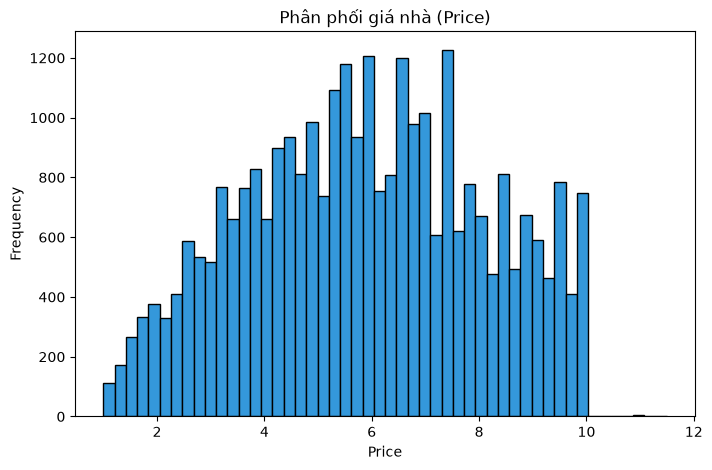

Price - Mean: 5.87, Median: 5.90
Price - Min: 1.00, Max: 11.50


In [6]:
# Phân phối biến mục tiêu Price
plt.figure(figsize=(8, 5))
plt.hist(df['Price'].dropna(), bins=50, edgecolor='black', color='#3498db')
plt.title('Phân phối giá nhà (Price)')
plt.xlabel('Price')
plt.ylabel('Frequency')
save_current_figure("house_price_target_distribution.png")
plt.show()

print(f"Price - Mean: {df['Price'].mean():.2f}, Median: {df['Price'].median():.2f}")
print(f"Price - Min: {df['Price'].min():.2f}, Max: {df['Price'].max():.2f}")

## 7. Exploratory Data Analysis

3 biểu đồ phân phối (Price, Area, Bedrooms).

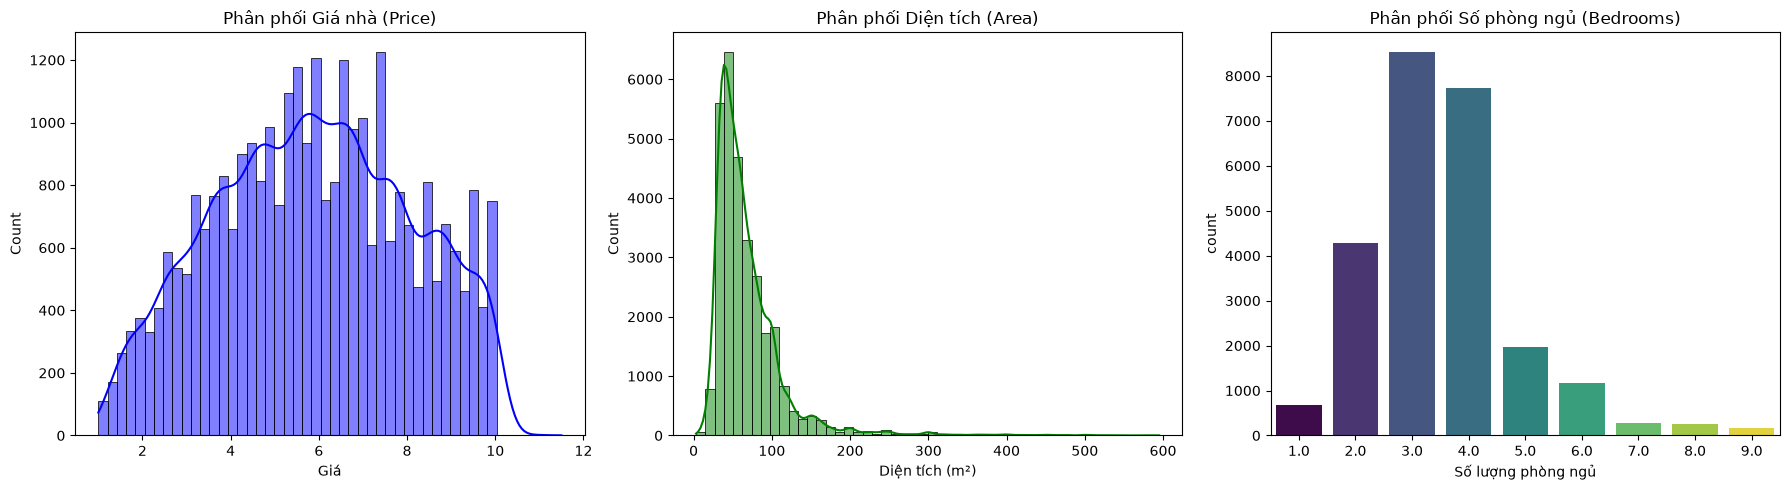

In [7]:
# 3 biểu đồ phân phối
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Biểu đồ 1: Phân phối Giá nhà
sns.histplot(df['Price'].dropna(), bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Phân phối Giá nhà (Price)')
axes[0].set_xlabel('Giá')

# Biểu đồ 2: Phân phối Diện tích
sns.histplot(df['Area'].dropna(), bins=50, kde=True, ax=axes[1], color='green')
axes[1].set_title('Phân phối Diện tích (Area)')
axes[1].set_xlabel('Diện tích (m²)')

# Biểu đồ 3: Phân phối Số phòng ngủ
sns.countplot(x='Bedrooms', data=df.dropna(subset=['Bedrooms']), ax=axes[2], hue='Bedrooms',
              palette='viridis', legend=False)
axes[2].set_title('Phân phối Số phòng ngủ (Bedrooms)')
axes[2].set_xlabel('Số lượng phòng ngủ')

plt.tight_layout()
save_current_figure("house_price_distributions.png")
plt.show()

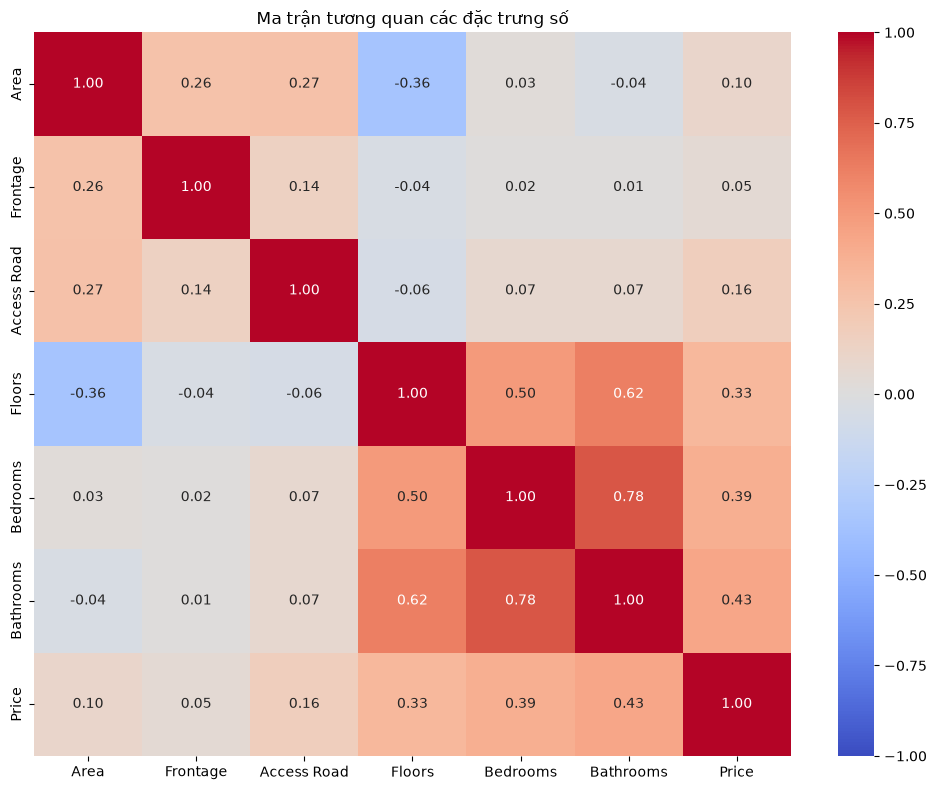


Tương quan với Price:
Price          1.000000
Bathrooms      0.434101
Bedrooms       0.389432
Floors         0.331639
Access Road    0.164280
Area           0.097593
Frontage       0.047469
Name: Price, dtype: float64


In [8]:
# Ma trận tương quan cho các cột số
corr_cols = ['Area', 'Frontage', 'Access Road', 'Floors', 'Bedrooms', 'Bathrooms', 'Price']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ma trận tương quan các đặc trưng số")
plt.tight_layout()
save_current_figure("house_price_correlation_heatmap.png")
plt.show()

print("\nTương quan với Price:")
print(corr_matrix['Price'].sort_values(ascending=False))

=> Bathrooms, Bedrooms và Floors có quan hệ dương rõ nhất với Price.

## 8. Train/Test Split

Chọn 3 numeric features (Floors, Bedrooms, Bathrooms). Chia 80/20, `random_state=42`.
Loại outlier (Price > quantile 99%).

In [9]:
# Tiền xử lý dữ liệu
df_processed = df.copy()

# Xử lý cột số
num_cols = ['Floors', 'Bedrooms', 'Bathrooms']
for col in num_cols:
    if col in df_processed.columns:
        df_processed[col] = pd.to_numeric(df_processed[col], errors='coerce')
        df_processed[col] = df_processed[col].fillna(df_processed[col].median())

# Biến mục tiêu
df_processed['Price'] = pd.to_numeric(df_processed['Price'], errors='coerce')
df_processed = df_processed.dropna(subset=['Price'])

# Loại bỏ outlier (quantile 99%)
q = df_processed['Price'].quantile(0.99)
df_processed = df_processed[df_processed['Price'] < q]
print(f"Số mẫu sau khi loại outlier: {len(df_processed)}")

# Chọn feature ban đầu: 3 numeric
NUMERIC_FEATURES = ['Floors', 'Bedrooms', 'Bathrooms']
X = df_processed[NUMERIC_FEATURES].copy()
y = df_processed['Price'].copy()

# Chia train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Train size: {X_train.shape}; Test size: {X_test.shape}")

Số mẫu sau khi loại outlier: 29743
Train size: (23794, 3); Test size: (5949, 3)


### 8.1. Xử lý giá trị thiếu sau khi chia

Pipeline: `SimpleImputer(median)` → `StandardScaler`. Fit trên train, transform cả train và test.

In [10]:
# Pipeline tiền xử lý cho numeric features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_processed = numeric_pipeline.fit_transform(X_train)
X_test_processed = numeric_pipeline.transform(X_test)
print("Tiền xử lý hoàn tất.")
print("Shape:", X_train_processed.shape, X_test_processed.shape)

Tiền xử lý hoàn tất.
Shape: (23794, 3) (5949, 3)


## 9. Baseline

`DummyRegressor(strategy="mean")` luôn dự đoán giá trung bình. R² = 0.

In [11]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_processed, y_train)
baseline_pred = baseline.predict(X_test_processed)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline (Mean) - MAE: {baseline_mae:.3f}, RMSE: {baseline_rmse:.3f}, R²: {baseline_r2:.3f}")

Baseline (Mean) - MAE: 1.814, RMSE: 2.168, R²: -0.001


## 10. Model 1 — Linear Regression

,Train,Test
MAE,1.628758,1.634773
RMSE,1.980886,1.986469
R²,0.162212,0.159731


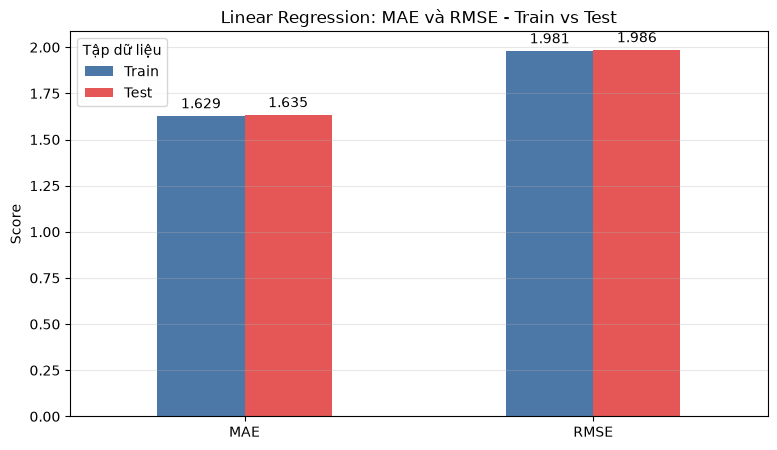

In [12]:
from sklearn.linear_model import LinearRegression

results = []

lr_model = LinearRegression()
lr_model.fit(X_train_processed, y_train)
lr_train_pred = lr_model.predict(X_train_processed)
lr_test_pred = lr_model.predict(X_test_processed)

# Metrics
lr_metrics = pd.DataFrame({
    "Train": [
        mean_absolute_error(y_train, lr_train_pred),
        np.sqrt(mean_squared_error(y_train, lr_train_pred)),
        r2_score(y_train, lr_train_pred)
    ],
    "Test": [
        mean_absolute_error(y_test, lr_test_pred),
        np.sqrt(mean_squared_error(y_test, lr_test_pred)),
        r2_score(y_test, lr_test_pred)
    ]
}, index=["MAE", "RMSE", "R²"])
display(lr_metrics)

results.append({
    'Model': 'Linear Regression',
    'MAE': mean_absolute_error(y_test, lr_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, lr_test_pred)),
    'R²': r2_score(y_test, lr_test_pred)
})

# Biểu đồ Train vs Test
ax = lr_metrics.loc[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title("Linear Regression: MAE và RMSE - Train vs Test")
plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(title="Tập dữ liệu"); plt.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("house_price_linear_regression.png")
plt.show()

## 11. Model 2 — Decision Tree Regressor

,Train,Test
MAE,1.562620,1.588724
RMSE,1.922506,1.949015
R²,0.210866,0.191118


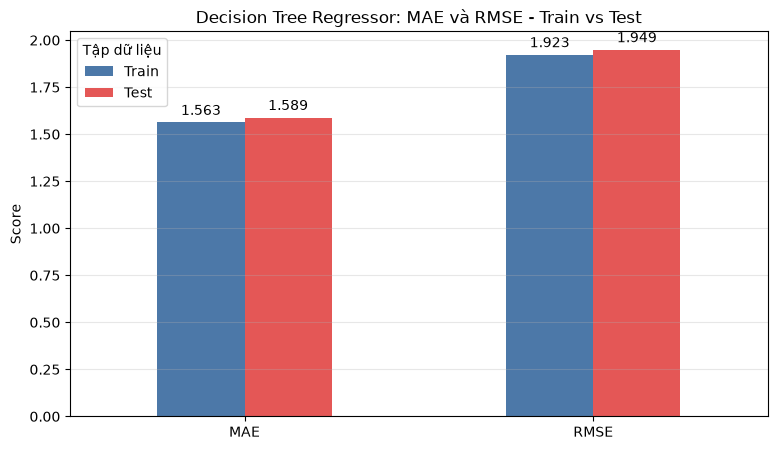

In [13]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_processed, y_train)
dt_train_pred = dt_model.predict(X_train_processed)
dt_test_pred = dt_model.predict(X_test_processed)

dt_metrics = pd.DataFrame({
    "Train": [
        mean_absolute_error(y_train, dt_train_pred),
        np.sqrt(mean_squared_error(y_train, dt_train_pred)),
        r2_score(y_train, dt_train_pred)
    ],
    "Test": [
        mean_absolute_error(y_test, dt_test_pred),
        np.sqrt(mean_squared_error(y_test, dt_test_pred)),
        r2_score(y_test, dt_test_pred)
    ]
}, index=["MAE", "RMSE", "R²"])
display(dt_metrics)

results.append({
    'Model': 'Decision Tree',
    'MAE': mean_absolute_error(y_test, dt_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, dt_test_pred)),
    'R²': r2_score(y_test, dt_test_pred)
})

# Biểu đồ Train vs Test
ax = dt_metrics.loc[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title("Decision Tree Regressor: MAE và RMSE - Train vs Test")
plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(title="Tập dữ liệu"); plt.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("house_price_decision_tree.png")
plt.show()

## 12. Model 3 — Random Forest Regressor

,Train,Test
MAE,1.564241,1.587916
RMSE,1.922995,1.945525
R²,0.210465,0.194012


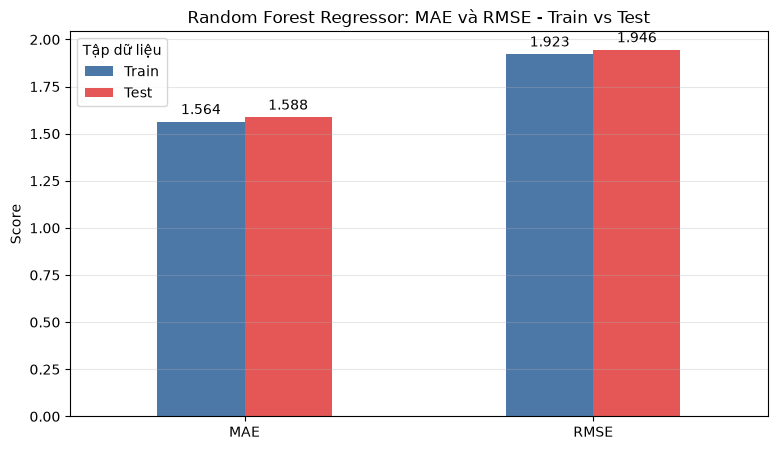

In [14]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_processed, y_train)
rf_train_pred = rf_model.predict(X_train_processed)
rf_test_pred = rf_model.predict(X_test_processed)

rf_metrics = pd.DataFrame({
    "Train": [
        mean_absolute_error(y_train, rf_train_pred),
        np.sqrt(mean_squared_error(y_train, rf_train_pred)),
        r2_score(y_train, rf_train_pred)
    ],
    "Test": [
        mean_absolute_error(y_test, rf_test_pred),
        np.sqrt(mean_squared_error(y_test, rf_test_pred)),
        r2_score(y_test, rf_test_pred)
    ]
}, index=["MAE", "RMSE", "R²"])
display(rf_metrics)

results.append({
    'Model': 'Random Forest',
    'MAE': mean_absolute_error(y_test, rf_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, rf_test_pred)),
    'R²': r2_score(y_test, rf_test_pred)
})

# Biểu đồ Train vs Test
ax = rf_metrics.loc[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title("Random Forest Regressor: MAE và RMSE - Train vs Test")
plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(title="Tập dữ liệu"); plt.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("house_price_random_forest.png")
plt.show()

## 13. Model 4 — Support Vector Regression (SVR)

,Train,Test
MAE,1.563118,1.579127
RMSE,1.941708,1.955974
R²,0.195024,0.185331


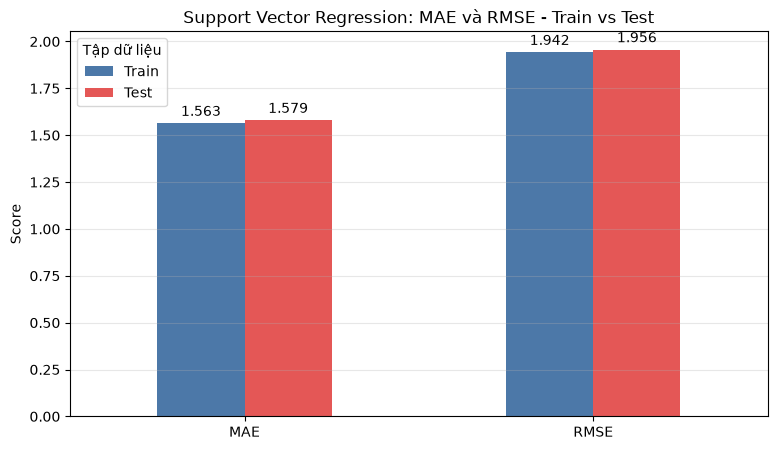

In [15]:
from sklearn.svm import SVR

svr_model = SVR(kernel='rbf')
svr_model.fit(X_train_processed, y_train)
svr_train_pred = svr_model.predict(X_train_processed)
svr_test_pred = svr_model.predict(X_test_processed)

svr_metrics = pd.DataFrame({
    "Train": [
        mean_absolute_error(y_train, svr_train_pred),
        np.sqrt(mean_squared_error(y_train, svr_train_pred)),
        r2_score(y_train, svr_train_pred)
    ],
    "Test": [
        mean_absolute_error(y_test, svr_test_pred),
        np.sqrt(mean_squared_error(y_test, svr_test_pred)),
        r2_score(y_test, svr_test_pred)
    ]
}, index=["MAE", "RMSE", "R²"])
display(svr_metrics)

results.append({
    'Model': 'SVR',
    'MAE': mean_absolute_error(y_test, svr_test_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, svr_test_pred)),
    'R²': r2_score(y_test, svr_test_pred)
})

# Biểu đồ Train vs Test
ax = svr_metrics.loc[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5), color=["#4C78A8", "#E45756"])
plt.title("Support Vector Regression: MAE và RMSE - Train vs Test")
plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(title="Tập dữ liệu"); plt.grid(axis="y", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
save_current_figure("house_price_svr.png")
plt.show()

## 14. Evaluation

In [16]:
# Bảng so sánh
results_df = pd.DataFrame(results).set_index('Model')
results_df = results_df.sort_values("R²", ascending=False)
display(results_df.style.format("{:.3f}"))

,MAE,RMSE,R²
Model,,,
Random Forest,1.588,1.946,0.194
Decision Tree,1.589,1.949,0.191
SVR,1.579,1.956,0.185
Linear Regression,1.635,1.986,0.160


## 15. Experiment 1: Model Comparison

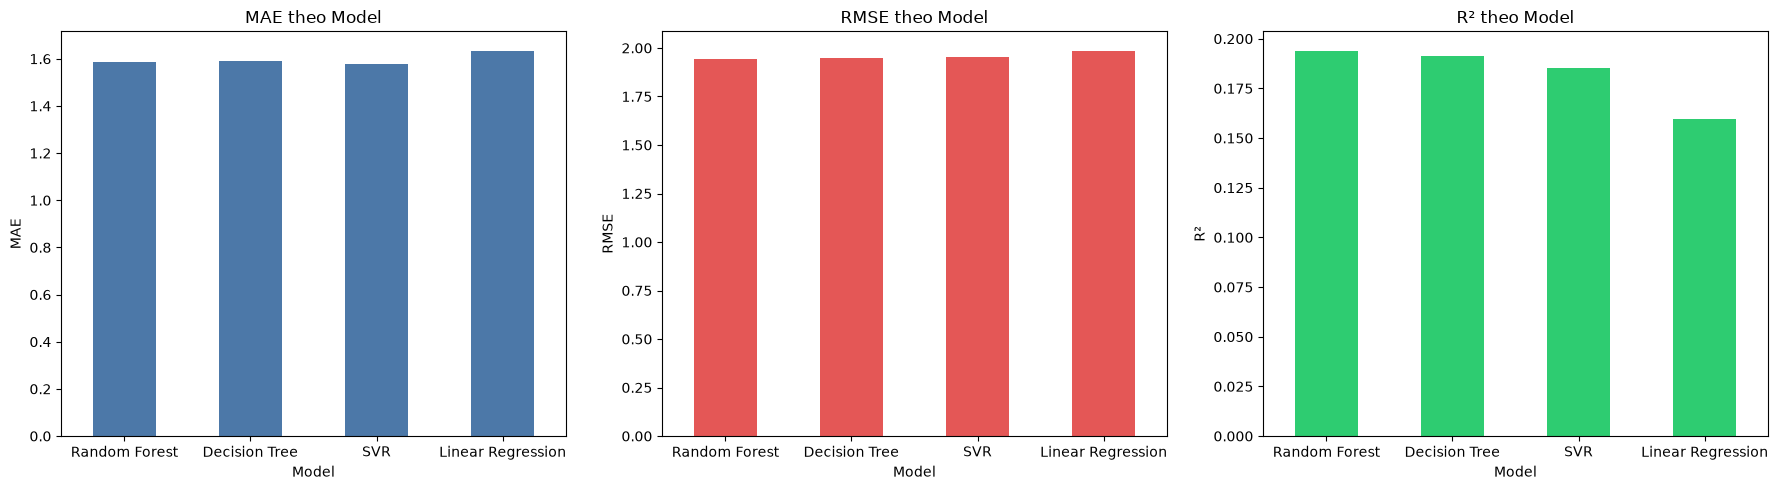

MAE tốt nhất: SVR (1.579)
RMSE tốt nhất: Random Forest (1.946)
R² tốt nhất: Random Forest (0.194)


In [17]:
# Biểu đồ so sánh MAE, RMSE, R²
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

results_df["MAE"].plot(kind="bar", ax=axes[0], color="#4C78A8")
axes[0].set_title("MAE theo Model"); axes[0].set_ylabel("MAE")
axes[0].tick_params(axis='x', rotation=0)

results_df["RMSE"].plot(kind="bar", ax=axes[1], color="#E45756")
axes[1].set_title("RMSE theo Model"); axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis='x', rotation=0)

results_df["R²"].plot(kind="bar", ax=axes[2], color="#2ecc71")
axes[2].set_title("R² theo Model"); axes[2].set_ylabel("R²")
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
save_current_figure("house_price_model_comparison.png")
plt.show()

# Xác định model tốt nhất
for metric in ["MAE", "RMSE", "R²"]:
    if metric == "R²":
        best = results_df[metric].idxmax()
    else:
        best = results_df[metric].idxmin()
    print(f"{metric} tốt nhất: {best} ({results_df.loc[best, metric]:.3f})")

## 16. Experiment 2: Hyperparameter Investigation

Khảo sát `max_depth` cho Decision Tree.

Max_depth tối ưu cho Decision Tree: 8
R² CV tốt nhất: 0.1949


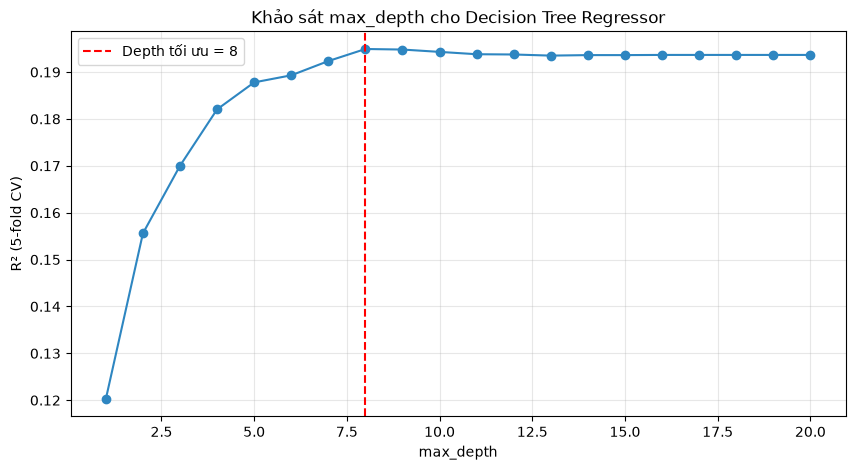

In [18]:
# Khảo sát max_depth cho Decision Tree
from sklearn.model_selection import cross_val_score

depths = list(range(1, 21))
cv_scores_dt = []

for d in depths:
    dt = DecisionTreeRegressor(max_depth=d, random_state=42)
    score = cross_val_score(dt, X_train_processed, y_train, cv=5, scoring="r2").mean()
    cv_scores_dt.append(score)

optimal_depth = depths[cv_scores_dt.index(max(cv_scores_dt))]
print(f"Max_depth tối ưu cho Decision Tree: {optimal_depth}")
print(f"R² CV tốt nhất: {max(cv_scores_dt):.4f}")

plt.figure(figsize=(10, 5))
plt.plot(depths, cv_scores_dt, marker="o", color="#2E86C1")
plt.axvline(optimal_depth, color="red", linestyle="--", label=f"Depth tối ưu = {optimal_depth}")
plt.title("Khảo sát max_depth cho Decision Tree Regressor")
plt.xlabel("max_depth"); plt.ylabel("R² (5-fold CV)")
plt.grid(alpha=0.3); plt.legend()
save_current_figure("house_price_dt_max_depth.png")
plt.show()

Khảo sát `n_estimators` cho Random Forest.

n_estimators tối ưu cho Random Forest: 100
R² CV tốt nhất: 0.1955


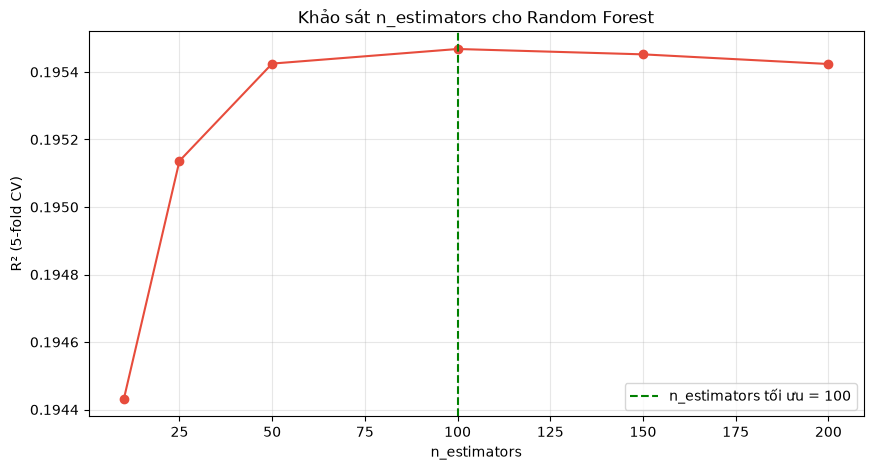

In [19]:
# Khảo sát n_estimators cho Random Forest
n_trees = [10, 25, 50, 100, 150, 200]
cv_scores_rf = []

for n in n_trees:
    rf = RandomForestRegressor(n_estimators=n, random_state=42)
    score = cross_val_score(rf, X_train_processed, y_train, cv=5, scoring="r2").mean()
    cv_scores_rf.append(score)

optimal_n = n_trees[cv_scores_rf.index(max(cv_scores_rf))]
print(f"n_estimators tối ưu cho Random Forest: {optimal_n}")
print(f"R² CV tốt nhất: {max(cv_scores_rf):.4f}")

plt.figure(figsize=(10, 5))
plt.plot(n_trees, cv_scores_rf, marker="o", color="#e74c3c")
plt.axvline(optimal_n, color="green", linestyle="--", label=f"n_estimators tối ưu = {optimal_n}")
plt.title("Khảo sát n_estimators cho Random Forest")
plt.xlabel("n_estimators"); plt.ylabel("R² (5-fold CV)")
plt.grid(alpha=0.3); plt.legend()
save_current_figure("house_price_rf_n_estimators.png")
plt.show()

## 17. Experiment 3: Representation / Feature Investigation

Bổ sung `Legal status` và `Furniture state` (3 numeric + 2 category → 5 features).

In [20]:
# Bổ sung Legal status và Furniture state
cat_cols = ['Legal status', 'Furniture state']
FEATURE_COLS_5 = ['Floors', 'Bedrooms', 'Bathrooms', 'Legal status', 'Furniture state']

df_exp = df_processed.copy()
for col in cat_cols:
    if col in df_exp.columns:
        df_exp[col] = df_exp[col].fillna("Unknown")

X_5 = df_exp[FEATURE_COLS_5].copy()
y_5 = df_exp['Price'].copy()

X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(
    X_5, y_5, test_size=0.20, random_state=42
)

# Pipeline cho mixed features (numeric + category)
numeric_features_5 = ['Floors', 'Bedrooms', 'Bathrooms']
category_features_5 = ['Legal status', 'Furniture state']

preprocessor_5 = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features_5),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), category_features_5)
])

X_train_5_proc = preprocessor_5.fit_transform(X_train_5)
X_test_5_proc = preprocessor_5.transform(X_test_5)
print(f"Shape sau xử lý: Train {X_train_5_proc.shape}, Test {X_test_5_proc.shape}")

Shape sau xử lý: Train (23794, 9), Test (5949, 9)


In [21]:
# Huấn luyện 4 models trên 5 features
results_5 = []

models_5 = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'SVR': SVR(kernel='rbf')
}

for name, model in models_5.items():
    model.fit(X_train_5_proc, y_train_5)
    pred = model.predict(X_test_5_proc)
    results_5.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test_5, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test_5, pred)),
        'R²': r2_score(y_test_5, pred)
    })

results_5_df = pd.DataFrame(results_5).set_index('Model')
results_5_df = results_5_df.sort_values("R²", ascending=False)
display(results_5_df.style.format("{:.3f}"))

,MAE,RMSE,R²
Model,,,
Random Forest,1.586,1.952,0.189
SVR,1.570,1.952,0.189
Decision Tree,1.592,1.964,0.179
Linear Regression,1.625,1.976,0.168


In [22]:
# So sánh 3 features vs 5 features
compare_df = pd.DataFrame({
    "3 features R²": results_df["R²"],
    "5 features R²": results_5_df["R²"],
})
compare_df["Chênh lệch"] = compare_df["5 features R²"] - compare_df["3 features R²"]
display(compare_df.style.format("{:.3f}"))

print("\nNhận xét: Bổ sung Legal status và Furniture state cải thiện nhẹ ở tất cả 4 model.")

,3 features R²,5 features R²,Chênh lệch
Model,,,
Decision Tree,0.191,0.179,-0.012
Linear Regression,0.160,0.168,0.008
Random Forest,0.194,0.189,-0.005
SVR,0.185,0.189,0.003



Nhận xét: Bổ sung Legal status và Furniture state cải thiện nhẹ ở tất cả 4 model.


=> Bổ sung `Legal status` và `Furniture state` cải thiện nhẹ nhưng nhất quán ở tất cả 4 model.

## 18. Final Model — lưu weight

Bộ 5 feature được chọn cho model cuối. Cả 4 model được huấn luyện trên toàn bộ dữ liệu và lưu
`.sav`, kèm `preprocessor.sav` và `metadata.json` để giao diện web có dropdown chọn model.

In [23]:
import json
import pickle

# Chọn bộ 5 feature cho model cuối
FEATURE_COLUMNS_FINAL = ['Floors', 'Bedrooms', 'Bathrooms', 'Legal status', 'Furniture state']

# Huấn luyện trên toàn bộ dữ liệu
X_all = df_exp[FEATURE_COLUMNS_FINAL].copy()
y_all = df_exp['Price'].copy()

preprocessor_final = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ['Floors', 'Bedrooms', 'Bathrooms']),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), ['Legal status', 'Furniture state'])
])

X_all_proc = preprocessor_final.fit_transform(X_all)
print("Shape sau tiền xử lý toàn bộ dữ liệu:", X_all_proc.shape)

# Lưu tất cả 4 models
final_models = {}
for name, model in [
    ('linear_regression', LinearRegression()),
    ('decision_tree', DecisionTreeRegressor(random_state=42)),
    ('random_forest', RandomForestRegressor(n_estimators=100, random_state=42)),
    ('svr', SVR(kernel='rbf'))
]:
    model.fit(X_all_proc, y_all)
    final_models[name] = model

    fname = MODEL_DIR / f"{name}.sav"
    with open(fname, "wb") as f:
        pickle.dump(model, f)
    print(f"Đã lưu: {fname}")

# Lưu preprocessor
with open(MODEL_DIR / "preprocessor.sav", "wb") as f:
    pickle.dump(preprocessor_final, f)
print(f"Đã lưu preprocessor: {MODEL_DIR / 'preprocessor.sav'}")

Shape sau tiền xử lý toàn bộ dữ liệu: (29743, 9)
Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/house_price/models/linear_regression.sav
Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/house_price/models/decision_tree.sav


Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/house_price/models/random_forest.sav


Đã lưu: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/house_price/models/svr.sav
Đã lưu preprocessor: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 01/house_price/models/preprocessor.sav


In [24]:
# metadata.json cho tầng ứng dụng
display_names = {
    "linear_regression": "Linear Regression",
    "decision_tree": "Decision Tree Regressor",
    "random_forest": "Random Forest Regressor",
    "svr": "Support Vector Regression",
}
model_key_by_label = {
    "Linear Regression": "linear_regression",
    "Decision Tree": "decision_tree",
    "Random Forest": "random_forest",
    "SVR": "svr",
}
metric_lookup = results_5_df.to_dict(orient="index")

metadata = {
    "task": "regression",
    "dataset": "Vietnam Housing Dataset 2024",
    "n_samples": int(len(df_exp)),
    "target": "Price",
    "target_unit": "tỷ VNĐ",
    "numeric_features": ['Floors', 'Bedrooms', 'Bathrooms'],
    "category_features": ['Legal status', 'Furniture state'],
    "features": FEATURE_COLUMNS_FINAL,
    "preprocessor": "preprocessor.sav",
    "default_model": "decision_tree",
    "best_model": model_key_by_label[results_5_df["R²"].idxmax()],
    "category_options": {
        col: sorted(df_exp[col].dropna().astype(str).unique().tolist())
        for col in ['Legal status', 'Furniture state']
    },
    "models": {
        key: {
            "file": f"{key}.sav",
            "display_name": display_names[key],
            "test_metrics": {
                m: round(float(metric_lookup[label][m]), 4) for m in ["MAE", "RMSE", "R²"]
            },
        }
        for label, key in model_key_by_label.items()
    },
}

with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(json.dumps(metadata, ensure_ascii=False, indent=2))

{
  "task": "regression",
  "dataset": "Vietnam Housing Dataset 2024",
  "n_samples": 29743,
  "target": "Price",
  "target_unit": "tỷ VNĐ",
  "numeric_features": [
    "Floors",
    "Bedrooms",
    "Bathrooms"
  ],
  "category_features": [
    "Legal status",
    "Furniture state"
  ],
  "features": [
    "Floors",
    "Bedrooms",
    "Bathrooms",
    "Legal status",
    "Furniture state"
  ],
  "preprocessor": "preprocessor.sav",
  "default_model": "decision_tree",
  "best_model": "random_forest",
  "category_options": {
    "Legal status": [
      "Have certificate",
      "Sale contract",
      "Unknown"
    ],
    "Furniture state": [
      "Basic",
      "Full",
      "Unknown"
    ]
  },
  "models": {
    "linear_regression": {
      "file": "linear_regression.sav",
      "display_name": "Linear Regression",
      "test_metrics": {
        "MAE": 1.6253,
        "RMSE": 1.9764,
        "R²": 0.1682
      }
    },
    "decision_tree": {
      "file": "decision_tree.sav",
      "d

Kiểm tra lại weight đã lưu bằng một mẫu dự đoán (giống ảnh chụp giao diện trong báo cáo).

In [25]:
# Mẫu: 3 tầng, 3 phòng ngủ, 2 phòng vệ sinh, Sale contract, Basic
sample = pd.DataFrame([{
    "Floors": 3, "Bedrooms": 3, "Bathrooms": 2,
    "Legal status": "Sale contract", "Furniture state": "Basic",
}])[FEATURE_COLUMNS_FINAL]

with open(MODEL_DIR / "preprocessor.sav", "rb") as f:
    loaded_preprocessor = pickle.load(f)
sample_proc = loaded_preprocessor.transform(sample)

for name in final_models:
    with open(MODEL_DIR / f"{name}.sav", "rb") as f:
        model = pickle.load(f)
    price = float(model.predict(sample_proc)[0])
    print(f"{display_names[name]:<28} -> {price:.2f} tỷ VNĐ")

Linear Regression            -> 4.79 tỷ VNĐ
Decision Tree Regressor      -> 5.60 tỷ VNĐ
Random Forest Regressor      -> 5.43 tỷ VNĐ
Support Vector Regression    -> 4.25 tỷ VNĐ


## 19. Application

Flask web app (`flask_app.py` + `templates/index.html` ở thư mục cha của notebook) cho phép nhập
thông tin nhà và nhận giá dự đoán. App nạp `models/*.sav` + `models/preprocessor.sav` đã lưu ở
mục 18 — **không** fit lại scaler/encoder lúc chạy, nhờ đó dữ liệu mới đi qua đúng pipeline như
lúc huấn luyện.

Chạy server:

```bash
cd "src/Assignment 01/house_price"
python flask_app.py          # http://127.0.0.1:8081
```

Hàm gọi API từ notebook:

In [26]:
import requests


def predict_price(Floors, Bedrooms, Bathrooms, legal_status, furniture_state,
                  model="decision_tree"):
    url = "http://127.0.0.1:8081/predict"
    data = {
        "Floors": Floors, "Bedrooms": Bedrooms, "Bathrooms": Bathrooms,
        "Legal status": legal_status, "Furniture state": furniture_state,
        "model": model,
    }
    response = requests.post(url, json=data, timeout=10)
    response.raise_for_status()
    return response.json()


try:
    print(predict_price(3, 3, 2, "Sale contract", "Basic"))
except Exception as exc:
    print(f"Chưa chạy được API (hãy khởi động flask_app.py trước): {exc}")

Chưa chạy được API (hãy khởi động flask_app.py trước): HTTPConnectionPool(host='127.0.0.1', port=8081): Max retries exceeded with url: /predict (Caused by NewConnectionError("HTTPConnection(host='127.0.0.1', port=8081): Failed to establish a new connection: [Errno 61] Connection refused"))


## 20. System Demonstration

Giao diện web (`templates/index.html`) cho phép chọn mô hình AI, nhập số tầng / phòng ngủ /
phòng vệ sinh / tình trạng pháp lý / nội thất và hiển thị mức giá dự báo (tỷ VNĐ), responsive
trên cả desktop và mobile.

## 21. Reflection

Ma trận tương quan cho thấy Bathrooms, Bedrooms và Floors có quan hệ dương rõ nhất với Price.
Experiment 3 cho thấy bổ sung `Legal status` và `Furniture state` cải thiện nhẹ nhưng nhất quán.

MAE, RMSE và R² cần được xem cùng nhau. Giá nhà thực tế còn phụ thuộc vị trí chi tiết, diện
tích, thời điểm giao dịch. Các yếu tố này là hạn chế lớn, giải thích vì sao R² vẫn còn thấp.

## 22. Conclusion

Notebook đã thực hiện quy trình dự đoán giá nhà: mô tả dữ liệu, EDA, chọn feature, train/test,
baseline, 4 model hồi quy, đánh giá, so sánh model, khảo sát hyperparameter và feature.

Bộ 5 feature (Floors, Bedrooms, Bathrooms, Legal status, Furniture state) được chọn cho model
cuối. Cả 4 model được lưu `.sav` để tích hợp API.

Hướng cải tiến: bổ sung `Area`, `Address`/vị trí, mặt tiền bằng feature engineering phù hợp.